# Many sites, one model: pooled hyperparameters over ragged station records

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/pyrox/blob/main/docs/notebooks/ssm/ssm_hierarchical_sites.ipynb)

[Example 1](ssm_one_site.ipynb) fitted one station. Here we fit a small network of stations whose records start and end on different days, have different lengths and have their own gaps. This is what a real station archive looks like. Two of the stations have only a month of data. That is too little to learn a kernel from, so on their own their hyperparameters are barely constrained. We pad the records to one shape with `pad_sites` and run one Markov-GP marginal likelihood per station under `jax.vmap`. The stations share what they have in common through population-level priors on the kernel hyperparameters, so the short stations borrow strength from the long ones.

**pyrox-ssm capability shown:** `pad_sites`, which pads ragged per-station series to one `(N_Ω, N)` grid and returns the observation mask, and `MarkovGPPrior.log_marginal(..., mask=...)` vmapped over stations inside a `numpyro.plate`, so one NumPyro model holds every station with its own hyperparameters, and `MarkovGPPrior.condition(..., mask=...).predict(...)` vmapped over posterior draws and stations, which gives every station's posterior predictive on a dense grid. **Cost:** every log-density evaluation is one Kalman filter pass per station, $\mathcal{O}(N_\Omega N D_x^3)$ in the number of stations $N_\Omega$, the padded record length $N$ and the state dimension $D_x$. The vmapped stations run as one batched filter, so they share the sequential scan over the $N$ steps. We measure the wall-clock times of every fit, of the predictions and of one gradient in section 8.

**What you'll learn:**

1. How to turn ragged station records into padded arrays and a mask with `pad_sites`, and why the padding changes no station's likelihood.
2. How to write a hierarchical Markov-GP model as a plain NumPyro function, with per-station kernel hyperparameters drawn around population values in a non-centred form.
3. How to predict every station through its gaps, before its record starts and after it ends, averaged over the posterior draws.
4. How partial pooling pulls the estimates and the predictions of a short record towards the population, compared with fitting that record on its own.

The single-station model, its priors and the Kalman marginal likelihood are explained in [Example 1](ssm_one_site.ipynb), and we reuse them here without deriving them again.

## Background

The network is a set $\Omega_y$ of $N_\Omega \equiv N_{\Omega_y} = 6$ stations, indexed by $n = 1, \ldots, N_\Omega$. Station $n$ reported on the days $\mathcal{T}_{y,n}$, and it has $N_n \equiv \vert \mathcal{T}_{y,n} \vert$ daily mean temperatures $y_{n,k}$ (°C) on the days $t_{n,k} \in \mathcal{T}_{y,n}$, $k = 1, \ldots, N_n$. The days are strictly increasing within a station, and a gap is simply a day that is not in $\mathcal{T}_{y,n}$. Each station follows the model of Example 1,

$$y_{n,k} = c_n + \mu(t_{n,k}) + f_n(t_{n,k}) + \varepsilon_{n,k}$$

$$\mu(t) = a \cos(\omega t) + b \sin(\omega t)$$

$$f_n \sim \mathcal{GP}(0, k_\text{Matérn-3/2}(t, t'; \sigma_{f,n}^2, \ell_n))$$

$$\varepsilon_{n,k} \sim \mathcal{N}(0, \sigma_\varepsilon^2)$$

with $\omega = 2\pi / 365.25 \text{ days}^{-1}$ as before, where we have moved the mean temperature $c_n \in \mathbb{R}$ (°C) out of the seasonal cycle $\mu(t)$. We pool the parameters at three levels, each for a physical reason:

1. The offset $c_n$ is not pooled at all, as it depends on the station's elevation and siting.
2. The seasonal amplitudes $a, b \in \mathbb{R}$ (°C) are shared by every station (complete pooling), because the stations sit in one region and see the same annual cycle. So is the noise variance $\sigma_\varepsilon^2 \in \mathbb{R}_{>0}$, because every station has the same type of sensor.
3. The weather anomaly differs from station to station, but not by much, so its kernel variance $\sigma_{f,n}^2$ and lengthscale $\ell_n$ (days) are partially pooled.

For the partial pooling we write the two hyperparameters in log form, $\boldsymbol{\theta}_n = (\log \sigma_{f,n}^2, \log \ell_n) \in \mathbb{R}^{2}$, and draw them around a population mean $\boldsymbol{\mu}_\theta \in \mathbb{R}^{2}$ with a population spread $\boldsymbol{\tau}_\theta \in \mathbb{R}^{2}_{>0}$,

$$\boldsymbol{\theta}_n \sim \mathcal{N}(\boldsymbol{\mu}_\theta, \mathrm{diag}(\boldsymbol{\tau}_\theta^2))$$

If $\boldsymbol{\tau}_\theta$ is small the stations share one kernel, and if it is large each station is on its own, so the data decide how much the stations pool. With six stations $\boldsymbol{\tau}_\theta$ is poorly known. In this centred form the posterior of each $\boldsymbol{\theta}_n$ narrows as $\boldsymbol{\tau}_\theta$ shrinks, which makes a funnel that NUTS cannot step through. So we sample the equivalent non-centred form, in which the standardised offsets $\mathbf{z}_n \in \mathbb{R}^{2}$ are a priori independent of the population,

$$\boldsymbol{\theta}_n = \boldsymbol{\mu}_\theta + \boldsymbol{\tau}_\theta \odot \mathbf{z}_n$$

$$\mathbf{z}_n \sim \mathcal{N}(\mathbf{0}, \mathbf{I}_2)$$

The offset $c_n$ gets Example 1's prior $\mathcal{N}(10, 10^2)$. A Gaussian constant plus a GP is again a GP, so we do not sample $c_n$ at all and fold it into the anomaly's prior instead,

$$c_n + f_n \sim \mathcal{GP}(10, 10^2 + k_\text{Matérn-3/2}(t, t'; \sigma_{f,n}^2, \ell_n))$$

In state-space form the constant kernel is a one-dimensional state that never changes (`ConstantSDE`), which `SumSDE` stacks with the two-dimensional Matérn-3/2 state, so $D_x = 3$ and the Kalman filter integrates $c_n$ out together with the path. This removes six sampled values that would be strongly correlated with $a$ and $b$, which matters for NUTS (section 4).

To vmap one Kalman filter over the stations, every station needs a record of the same length. `pad_sites` extends station $n$ after its last day to $N = \max_n N_n$ steps at its median spacing $\delta_n$, so $t_{n,N_n+j} = t_{n,N_n} + j \delta_n$ for $j = 1, \ldots, N - N_n$. It also returns the mask $o_{n,k} \in \{0, 1\}$, which is 1 on the $N_n$ real days. A masked step runs only the filter's predict step, so the padding adds exactly zero to the log marginal. The model's log likelihood is then a sum of Example 1's masked log marginals over the stations,

$$\log p(\mathbf{Y} \mid a, b, \boldsymbol{\Theta}, \sigma_\varepsilon^2) = \sum_{n=1}^{N_\Omega} \sum_{k=1}^{N} o_{n,k} \log \mathcal{N}(y_{n,k}; 10 + \mu(t_{n,k}) + \mathbf{H} \boldsymbol{\mu}_{x,n,k \mid k-1}, \mathbf{H} \boldsymbol{\Sigma}_{x,n,k \mid k-1} \mathbf{H}^\top + \sigma_\varepsilon^2)$$

where $\mathbf{Y} \in \mathbb{R}^{N_\Omega \times N}$ stacks the padded records as rows and $\boldsymbol{\Theta} \in \mathbb{R}^{N_\Omega \times 2}$ the $\boldsymbol{\theta}_n$. Here $\boldsymbol{\mu}_{x,n,k \mid k-1} \in \mathbb{R}^{D_x}$ and $\boldsymbol{\Sigma}_{x,n,k \mid k-1} \in \mathbb{R}^{D_x \times D_x}$ are station $n$'s one-step-ahead state mean and covariance, and the measurement row $\mathbf{H} \in \mathbb{R}^{1 \times D_x}$ adds the constant to the Matérn-3/2 value.

## Setup

We detect Colab and install `pyrox`, `pyrox-gp[colab]` (which pulls in `matplotlib` and `watermark`) and `pyrox-ssm` only when the notebook runs there.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "pyrox @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox",
            "pyrox-gp[colab] @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-gp",
            "pyrox-ssm @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-ssm",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import time

import einx
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
from numpyro import handlers
from numpyro.infer import MCMC, NUTS, init_to_median
from pyrox_ssm import (
    ConstantSDE,
    MarkovGPPrior,
    MaternSDE,
    SumSDE,
    markov_gp_from_innovations,
    pad_sites,
)


# two CPU devices, so the two NUTS chains run in parallel
numpyro.set_host_device_count(2)
jax.config.update("jax_enable_x64", True)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark", "-v -m -p jax,equinox,numpyro,gaussx,pyrox,pyrox_ssm,matplotlib"
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.13.0

jax       : 0.10.2
equinox   : 0.13.8
numpyro   : 0.21.0
gaussx    : 0.6.15
pyrox     : 0.2.1
pyrox_ssm : 0.1.0
matplotlib: 3.10.9

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. A network of ragged station records

We simulate one year of a six-station network from the model itself, so that we know every true parameter. The seasonal cycle is Example 1's (an 8 °C annual cycle with its coldest point near 1 January). The sensor noise is again 0.5 °C, and the station offsets range from 7.5 to 12 °C. The population of anomaly kernels is centred on Example 1's values, a variance of $(2 \text{ °C})^2$ and a four-day lengthscale. Its spread is 0.3 in log units (about ±35 %), and each station's $\boldsymbol{\theta}_n$ is one draw from it.

The stations then report on their own schedules. Stations 1 to 4 each cover about four months, starting and ending in different seasons. Station 2 has a 25-day logger outage, station 3 misses another 30 % of its days at random, and station 4 has a 15-day outage. Stations 5 and 6 span only 35 and 30 days. As in Example 1, every station also misses each day with probability 0.08. We keep only the days a station reported. So each record is a pair of arrays (days and values) of its own length, and the records cannot be stacked into one array.

In [4]:
# Shapes: N_Ω = 6 stations; N_n days at station n; D_x = 2 (the Matérn-3/2 state)

# ω = 2π / 365.25 days⁻¹, the annual angular frequency
OMEGA = 2.0 * jnp.pi / 365.25


def seasonal(t, a, b):
    """Shared seasonal cycle μ(t) = a cos(ωt) + b sin(ωt)."""
    return a * jnp.cos(OMEGA * t) + b * jnp.sin(OMEGA * t)


truth_shared = {
    "cos_amp": -8.0,  # coldest near day 0 (1 January)
    "sin_amp": -1.5,
    "noise_var": 0.25,  # (0.5 °C)^2
}
# μ_θ = (log σ_f², log ℓ) of the population
truth_loc = jnp.log(jnp.array([4.0, 4.0]))  # → (2,)
# τ_θ, the population spread in log units
truth_scale = jnp.array([0.3, 0.3])  # → (2,)
# c_n, station offsets set by elevation and siting
truth_offset = jnp.array([10.0, 8.5, 11.5, 9.0, 12.0, 7.5])  # → (N_Ω,)

# (first day, last day + 1, outage or None, extra dropout rate)
schedule = [
    (0, 120, None, 0.0),
    (60, 190, (110, 135), 0.0),
    (150, 290, None, 0.3),
    (240, 365, (290, 305), 0.0),
    (170, 205, None, 0.0),
    (320, 350, None, 0.0),
]
n_stations = len(schedule)

key_theta, *station_keys = jr.split(jr.PRNGKey(2025), n_stations + 1)
# z_n ~ 𝒩(0, I₂)
z_true = jr.normal(key_theta, (n_stations, 2))  # → (N_Ω, 2)
# τ_θ ⊙ z_n
scaled_offsets = einx.multiply("p, n p -> n p", truth_scale, z_true)  # → (N_Ω, 2)
# θ_n = μ_θ + τ_θ ⊙ z_n
theta_true = einx.add("p, n p -> n p", truth_loc, scaled_offsets)  # → (N_Ω, 2)
# (σ_f,n², ℓ_n) = exp(θ_n)
kernel_true = jnp.exp(theta_true)  # → (N_Ω, 2)

times_per_station, y_per_station, latent_per_station = [], [], []
withheld_per_station = []
for n, (first, end, outage, extra) in enumerate(schedule):
    key_f, key_eps, key_gap = jr.split(station_keys[n], 3)
    # every day the station existed, t = first, …, end − 1
    days = jnp.arange(first, end, dtype=jnp.float64)  # → (n_days,)
    # today (pyrox_ssm)
    # k_Matérn-3/2(t, t'; σ_f,n², ℓ_n) as a linear SDE
    sde_n = MaternSDE(kernel_true[n, 0], kernel_true[n, 1], order=1)
    # today (pyrox_ssm)
    prior_n = MarkovGPPrior(sde_n, days)
    innovations = jr.normal(key_f, (days.shape[0], prior_n.state_dim))
    # today (pyrox_ssm)
    # f_n(t), the SDE run forward from the innovations
    f_n = markov_gp_from_innovations(prior_n, innovations)  # (n_days, D_x) → (n_days,)
    # c_n + μ(t)
    climatology_n = truth_offset[n] + seasonal(  # (n_days,) → (n_days,)
        days, truth_shared["cos_amp"], truth_shared["sin_amp"]
    )
    noise_std = jnp.sqrt(truth_shared["noise_var"])  # → ()
    # ε_n,k ~ 𝒩(0, σ_ε²)
    obs_noise = noise_std * jr.normal(key_eps, days.shape)  # → (n_days,)
    # y_n,k = c_n + μ(t_n,k) + f_n(t_n,k) + ε_n,k
    y_n = climatology_n + f_n + obs_noise  # → (n_days,)
    # a day is reported unless it drops out or falls in the outage
    reported = jr.uniform(key_gap, days.shape) >= 0.08 + extra  # → (n_days,) bool
    in_outage = jnp.zeros(days.shape, dtype=bool)  # → (n_days,) bool
    if outage is not None:
        in_outage = (days >= outage[0]) & (days < outage[1])  # → (n_days,) bool
    reported = reported & ~in_outage
    times_per_station.append(days[reported])
    y_per_station.append(y_n[reported])
    latent_per_station.append((days, climatology_n + f_n))
    # the days the station missed, with the values it would have reported
    withheld_per_station.append((days[~reported], y_n[~reported], in_outage[~reported]))

record_lengths = [int(t_n.shape[0]) for t_n in times_per_station]
print(f"{'station':<9}{'first day':>10}{'last day':>10}{'N_n':>6}{'σ_f²':>8}{'ℓ':>7}")
for n, t_n in enumerate(times_per_station):
    print(
        f"{n + 1:<9}{int(t_n[0]):>10}{int(t_n[-1]):>10}{record_lengths[n]:>6}"
        f"{float(kernel_true[n, 0]):>8.2f}{float(kernel_true[n, 1]):>7.2f}"
    )

station   first day  last day   N_n    σ_f²      ℓ
1                 0       119   104    5.48   3.83
2                60       189    95    3.68   4.83
3               151       287    87    6.79   4.80
4               240       363   102    3.57   2.97
5               170       204    34    2.54   3.00


6               320       349    28    4.16   3.62


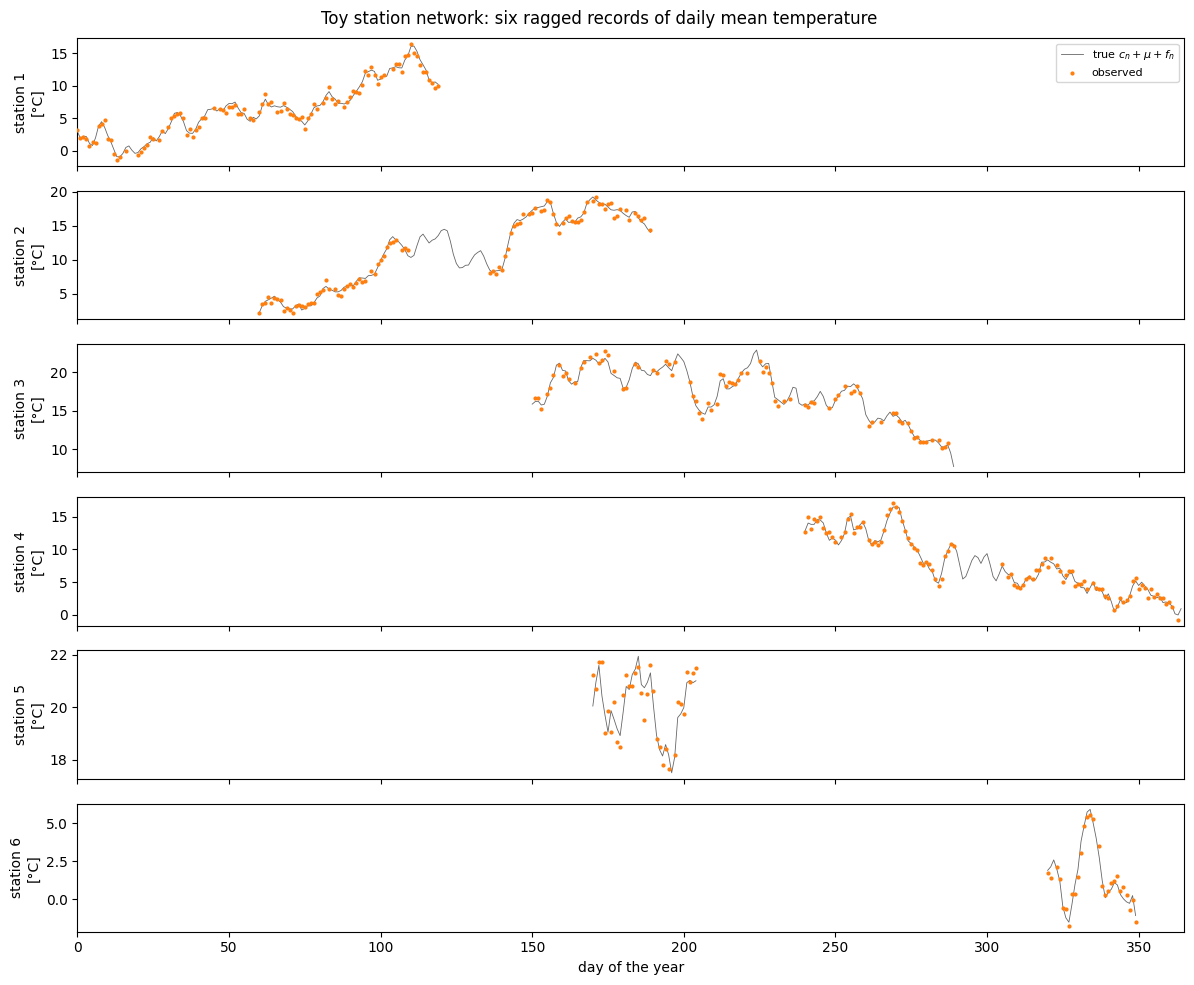

In [5]:
fig, axes = plt.subplots(n_stations, 1, figsize=(12, 10), sharex=True)
for n, ax in enumerate(axes):
    days, latent = latent_per_station[n]
    ax.plot(days, latent, "k-", lw=0.6, alpha=0.6, label=r"true $c_n + \mu + f_n$")
    ax.scatter(
        times_per_station[n], y_per_station[n], c="C1", s=4, zorder=5, label="observed"
    )
    ax.set_ylabel(f"station {n + 1}\n[°C]")
    ax.set_xlim(0, 365)
axes[0].legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("day of the year")
fig.suptitle("Toy station network: six ragged records of daily mean temperature")
plt.tight_layout()
plt.show()

## 2. Padding the records with `pad_sites`

`pad_sites` takes one array of days and one array of values per station. It returns three `(N_Ω, N)` arrays: the padded days $\mathbf{T}$, the padded values $\mathbf{Y}$ (zero after each record ends) and the mask $\mathbf{O}$. We print the mask's row sums, which must equal the record lengths. We also look at the end of a short station's row, where the padded days continue at its median spacing.

In [6]:
# Shapes: N_Ω = 6 stations; N = max_n N_n padded steps

# today (pyrox_ssm)
# T, Y, O with t_n,N_n+j = t_n,N_n + j δ_n and o_n,k = 1 for k ≤ N_n
times, y, mask = pad_sites(times_per_station, y_per_station)  # → 3 × (N_Ω, N)
n_padded = times.shape[1]
# ∑ₖ o_n,k = N_n
observed_per_station = einx.sum("n k -> n", mask)  # (N_Ω, N) bool → (N_Ω,)
print(f"times {times.shape}, y {y.shape}, mask {mask.shape} {mask.dtype}")
print(f"N = max_n N_n = {n_padded}")
print(f"mask row sums: {observed_per_station.tolist()}")
print(f"record lengths: {record_lengths}")
last = record_lengths[5]
print(f"station 6, steps k = {last - 2} to {last + 3}:")
print(f"  t    {np.asarray(times[5, last - 3 : last + 3]).round(1).tolist()}")
print(f"  y    {np.asarray(y[5, last - 3 : last + 3]).round(2).tolist()}")
print(f"  mask {np.asarray(mask[5, last - 3 : last + 3]).tolist()}")

times (6, 104), y (6, 104), mask (6, 104) bool
N = max_n N_n = 104
mask row sums: [104, 95, 87, 102, 34, 28]
record lengths: [104, 95, 87, 102, 34, 28]
station 6, steps k = 26 to 31:
  t    [347.0, 348.0, 349.0, 350.0, 351.0, 352.0]
  y    [-0.67, -0.04, -1.51, 0.0, 0.0, 0.0]
  mask [True, True, True, False, False, False]


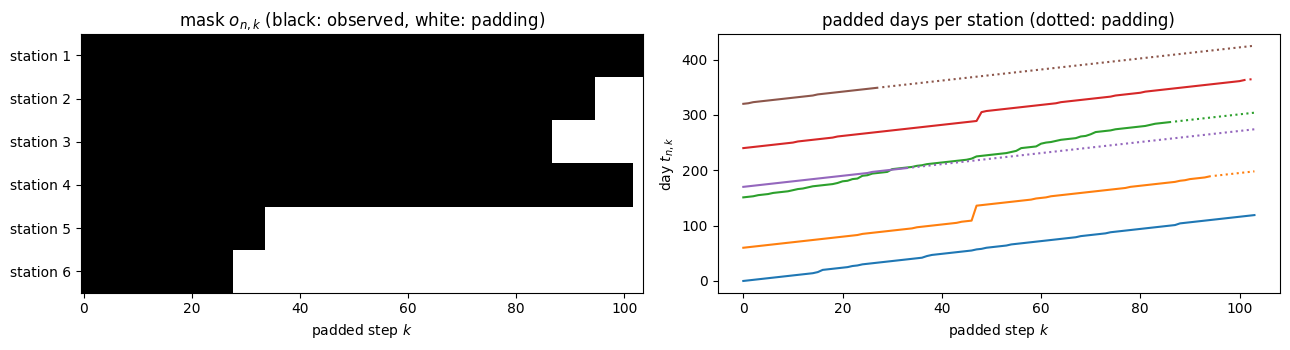

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
ax = axes[0]
ax.imshow(np.asarray(mask), aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(n_stations), [f"station {n + 1}" for n in range(n_stations)])
ax.set_xlabel("padded step $k$")
ax.set_title(r"mask $o_{n,k}$ (black: observed, white: padding)")
ax = axes[1]
for n in range(n_stations):
    steps = np.arange(n_padded)
    real = np.asarray(mask[n])
    ax.plot(steps[real], np.asarray(times[n])[real], f"C{n}-", lw=1.5)
    ax.plot(steps[~real], np.asarray(times[n])[~real], f"C{n}:", lw=1.5)
ax.set_xlabel("padded step $k$")
ax.set_ylabel(r"day $t_{n,k}$")
ax.set_title("padded days per station (dotted: padding)")
plt.tight_layout()
plt.show()

Each row is filled from the left, and every station keeps its own calendar. Step $k$ is a different day at each station, and a gap inside a record is a longer step, not a masked entry. Padding happens only after the last observation, so the padded steps are pure forecasts that the mask leaves out of the likelihood.

The per-station prior below is the one the model uses. `station_prior` builds the summed SDE of the background section, with the prior mean $10 + \mu(t)$ as `mean_fn`, and `station_log_marginal` calls its `log_marginal` with the station's mask row. We check the padding claim on station 6 with its true parameters, comparing the padded and masked log marginal with the one on its own unpadded record.

In [8]:
# Shapes: N = padded length; N_6 = station 6's record length; D_x = 3

# c_n ~ 𝒩(10, 10²), folded into the GP prior
OFFSET_MEAN = 10.0
OFFSET_VAR = 100.0


def station_prior(t_n, variance_n, lengthscale_n, a, b):
    # Shapes: N padded steps; D_x = 3 (constant + Matérn-3/2 state)
    # today (pyrox_ssm)
    # k(t, t') = 10², the offset c_n as a state that never changes
    offset_sde = ConstantSDE(variance=jnp.asarray(OFFSET_VAR))
    # today (pyrox_ssm)
    # k_Matérn-3/2(t, t'; σ_f,n², ℓ_n) as a linear SDE
    anomaly_sde = MaternSDE(variance=variance_n, lengthscale=lengthscale_n, order=1)
    # today (pyrox_ssm)
    # 10² + k_Matérn-3/2, the two states stacked block-diagonally
    sde = SumSDE(kernels=(offset_sde, anomaly_sde))
    # today (pyrox_ssm)
    # c_n + μ + f_n ~ 𝒢𝒫(10 + μ, 10² + k_Matérn-3/2) on station n's padded days
    return MarkovGPPrior(sde, t_n, mean_fn=lambda t: OFFSET_MEAN + seasonal(t, a, b))


def station_log_marginal(t_n, y_n, o_n, variance_n, lengthscale_n, a, b, noise_var):
    # Shapes: N padded steps
    # user
    prior = station_prior(t_n, variance_n, lengthscale_n, a, b)
    # today (pyrox_ssm)
    # log p(y_n ∣ ·) = ∑ₖ o_n,k log 𝒩(y_n,k; 10 + μ(t_n,k) + H μ_x,n,k∣k−1, H Σ_x,n,k∣k−1 Hᵀ + σ_ε²)
    return prior.log_marginal(y_n, noise_var, mask=o_n)  # (N,) → ()


shared_true = (
    truth_shared["cos_amp"],
    truth_shared["sin_amp"],
    truth_shared["noise_var"],
)
station_true = (kernel_true[5, 0], kernel_true[5, 1])
padded_lml = station_log_marginal(  # (N,) → ()
    times[5], y[5], mask[5], *station_true, *shared_true
)
unpadded_lml = station_log_marginal(  # (N_6,) → ()
    times_per_station[5],
    y_per_station[5],
    jnp.ones(record_lengths[5], dtype=bool),
    *station_true,
    *shared_true,
)
print(f"station 6, padded to {n_padded} steps: log p = {float(padded_lml):.12f}")
print(
    f"station 6, its own {record_lengths[5]} days: log p = {float(unpadded_lml):.12f}"
)
print(f"difference: {float(padded_lml - unpadded_lml):.2e}")

station 6, padded to 104 steps: log p = -42.182642701530
station 6, its own 28 days: log p = -42.182642701530
difference: 0.00e+00


The two log marginals agree exactly in float64, because the padded steps only run the filter's predict step and add nothing to the sum.

## 3. The hierarchical model as a plain NumPyro function

The global parameters are ordinary sample sites with Example 1's priors, $a, b \sim \mathcal{N}(0, 10^2)$ and $\sigma_\varepsilon^2 \sim \mathrm{LogNormal}(\log 0.1, 1)$. The population mean $\boldsymbol{\mu}_\theta$ gets a normal prior centred on Example 1's prior medians for $\sigma_f^2$ and $\ell$ (2 °C² and 7 days) with unit standard deviation. So before any data a station's $\boldsymbol{\theta}_n$ is at least as uncertain as it was in Example 1. The spread gets $\tau_{\theta,d} \sim \mathrm{HalfNormal}(0.5)$ for $d = 1, 2$, which says that stations in one region rarely differ by more than a factor of three. Inside `numpyro.plate("station", N_Ω)`, every sample site has one value per station.

pyrox-ssm has no helper for the non-centred step yet, so we write it inline in `noncentred_log_normal`. It samples $z_{n,d}$ from a standard normal, shifts and scales it, and records $\exp(\theta_{n,d})$ as a deterministic site, so the posterior of $\sigma_{f,n}^2$ and $\ell_n$ ends up in the trace. (NumPyro's `LocScaleReparam(centered=0)` does the same rewrite on a centred `Normal` site.) Then `jax.vmap` runs `station_log_marginal` over the station axis of the padded arrays, with the shared $a$, $b$ and $\sigma_\varepsilon^2$ broadcast. Finally, `numpyro.factor` adds the $N_\Omega$ log marginals as one factor site under the plate.

We do not call `markov_gp_factor` here. It registers its own factor site for one prior, so it cannot run under `jax.vmap`. The vmapped `log_marginal` with one factor is the pattern its docstring shows for ragged sites.

In [9]:
def noncentred_log_normal(name, loc, scale):
    """Positive per-station parameter exp(θ_n,d) with θ_n,d = μ_θ,d + τ_θ,d z_n,d."""
    # today (numpyro)
    # z_n,d ~ 𝒩(0, 1), one per station under the enclosing plate
    z = numpyro.sample(f"{name}_z", dist.Normal(0.0, 1.0))  # → (N_Ω,)
    # θ_n,d = μ_θ,d + τ_θ,d z_n,d
    log_value = loc + scale * z  # → (N_Ω,)
    # today (numpyro)
    # exp(θ_n,d), recorded in the trace
    return numpyro.deterministic(name, jnp.exp(log_value))  # → (N_Ω,)


def network_model(times, y, mask):
    # Shapes: N_Ω = 6 stations; N padded steps; D_θ = 7 + 2 N_Ω = 19 sampled values

    # today (numpyro): the global sample sites
    # a ~ 𝒩(0, 10²)
    a = numpyro.sample("cos_amp", dist.Normal(0.0, 10.0))
    # b ~ 𝒩(0, 10²)
    b = numpyro.sample("sin_amp", dist.Normal(0.0, 10.0))
    # σ_ε² ~ LogNormal(log 0.1, 1)
    noise_var = numpyro.sample("noise_var", dist.LogNormal(jnp.log(0.1), 1.0))
    # μ_θ,1 ~ 𝒩(log 2, 1), the population log-variance
    variance_loc = numpyro.sample("variance_loc", dist.Normal(jnp.log(2.0), 1.0))
    # τ_θ,1 ~ HalfNormal(0.5)
    variance_scale = numpyro.sample("variance_scale", dist.HalfNormal(0.5))
    # μ_θ,2 ~ 𝒩(log 7, 1), the population log-lengthscale
    lengthscale_loc = numpyro.sample("lengthscale_loc", dist.Normal(jnp.log(7.0), 1.0))
    # τ_θ,2 ~ HalfNormal(0.5)
    lengthscale_scale = numpyro.sample("lengthscale_scale", dist.HalfNormal(0.5))

    # today (numpyro): one value per station from here on
    with numpyro.plate("station", times.shape[0]):
        # user
        # σ_f,n² = exp(μ_θ,1 + τ_θ,1 z_n,1)
        variance = noncentred_log_normal(  # → (N_Ω,)
            "variance", variance_loc, variance_scale
        )
        # user
        # ℓ_n = exp(μ_θ,2 + τ_θ,2 z_n,2)
        lengthscale = noncentred_log_normal(  # → (N_Ω,)
            "lengthscale", lengthscale_loc, lengthscale_scale
        )
        # today (jax)
        # one Kalman filter per station, batched over the station axis
        per_station = jax.vmap(
            station_log_marginal, in_axes=(0, 0, 0, 0, 0, None, None, None)
        )
        # log p(y_n ∣ a, b, θ_n, σ_ε²) for n = 1, …, N_Ω
        log_marginals = per_station(  # (N_Ω, N) → (N_Ω,)
            times, y, mask, variance, lengthscale, a, b, noise_var
        )
        # today (numpyro)
        # log p(Y ∣ ·) = ∑ₙ log p(y_n ∣ ·), one factor term per station
        numpyro.factor("y", log_marginals)


def site_kind(site):
    """A short label for a trace site: plate, deterministic, factor or its family."""
    if site["type"] != "sample":
        return site["type"]
    fn = site["fn"]
    if isinstance(fn, dist.ExpandedDistribution):
        fn = fn.base_dist
    return "factor" if isinstance(fn, dist.Unit) else type(fn).__name__


# today (numpyro)
seeded_model = handlers.seed(network_model, rng_seed=0)
# today (numpyro)
trace = handlers.trace(seeded_model).get_trace(times, y, mask)
for name, site in trace.items():
    shape = tuple(jnp.shape(site["value"]))
    print(f"site {name!r:21} {site_kind(site):<14} value shape={shape}")

site 'cos_amp'             Normal         value shape=()
site 'sin_amp'             Normal         value shape=()
site 'noise_var'           LogNormal      value shape=()
site 'variance_loc'        Normal         value shape=()
site 'variance_scale'      HalfNormal     value shape=()
site 'lengthscale_loc'     Normal         value shape=()
site 'lengthscale_scale'   HalfNormal     value shape=()
site 'station'             plate          value shape=(6,)
site 'variance_z'          Normal         value shape=(6,)
site 'variance'            deterministic  value shape=(6,)
site 'lengthscale_z'       Normal         value shape=(6,)
site 'lengthscale'         deterministic  value shape=(6,)
site 'y'                   factor         value shape=(6, 0)


So the trace holds seven global sample sites, two sample sites with one value per station, the two deterministic per-station hyperparameters and one factor with one term per station. The latent paths and the offsets are integrated out by the Kalman filters, so NUTS sees $7 + 2 N_\Omega = 19$ unconstrained values whatever the record lengths.

## 4. NUTS

We run two chains of 150 draws after 250 warm-up steps, with a dense mass matrix as in Example 1. So warm-up adapts to the correlations between the seasonal amplitudes and the kernel hyperparameters. We start the chains at the prior medians (`init_to_median`). The warm-up is longer than Example 1's, because the dense mass matrix now has $19 \times 19$ entries to adapt. We split the CPU into two XLA devices at import (`numpyro.set_host_device_count(2)`), so `chain_method="parallel"` runs the two chains on two cores at once. The wall-clock time includes JIT compilation.

In [10]:
# Shapes: D_θ = 19 sampled values; 2 chains × 150 = 300 posterior draws

# today (numpyro)
nuts_kernel = NUTS(network_model, dense_mass=True, init_strategy=init_to_median)
# today (numpyro)
nuts = MCMC(
    nuts_kernel,
    num_warmup=250,
    num_samples=150,
    num_chains=2,
    chain_method="parallel",
    progress_bar=False,
)
t0 = time.perf_counter()
# today (numpyro)
# 300 draws from p(a, b, σ_ε², μ_θ, τ_θ, Z ∣ Y)
nuts.run(jr.PRNGKey(1), times, y, mask, extra_fields=("num_steps",))
jax.block_until_ready(nuts.get_samples())
nuts_seconds = time.perf_counter() - t0
nuts_samples = nuts.get_samples()  # → {name: (300,) or (300, N_Ω)}
nuts.print_summary(exclude_deterministic=True)
extra_fields = nuts.get_extra_fields()
n_div = int(extra_fields["diverging"].sum())  # → ()
n_grad = int(extra_fields["num_steps"].sum())  # → ()
print(
    f"NUTS wall-clock: {nuts_seconds:.1f} s for 2 chains x 400 iterations, "
    f"{n_div} divergences"
)
print(
    f"leapfrog steps after warm-up: {n_grad}, {n_grad / 300:.1f} per draw "
    f"(one batched Kalman filter pass over {n_stations} stations and its gradient each)"
)


                         mean       std    median      5.0%     95.0%     n_eff     r_hat
            cos_amp     -7.93      0.57     -7.95     -8.83     -7.01    210.54      1.00
    lengthscale_loc      1.45      0.14      1.44      1.25      1.70    476.14      1.00
  lengthscale_scale      0.16      0.12      0.13      0.00      0.31    159.54      0.99
   lengthscale_z[0]     -0.14      0.93     -0.13     -1.40      1.62    261.96      1.01
   lengthscale_z[1]      0.73      0.86      0.81     -0.78      2.08    264.35      1.01
   lengthscale_z[2]     -0.11      0.79     -0.16     -1.51      0.98    303.33      1.00
   lengthscale_z[3]     -0.46      0.81     -0.53     -1.72      0.76    350.46      1.00
   lengthscale_z[4]     -0.19      1.01     -0.17     -1.94      1.28    231.05      1.00
   lengthscale_z[5]     -0.10      0.84     -0.09     -1.62      1.17    379.80      0.99
          noise_var      0.27      0.04      0.27      0.21      0.34    415.51      1.00
         

NUTS wall-clock: 97.5 s for 2 chains x 400 iterations, 0 divergences
leapfrog steps after warm-up: 6660, 22.2 per draw (one batched Kalman filter pass over 6 stations and its gradient each)


Both chains mixed well: we get no divergences, every $\hat{R}$ is between 0.99 and 1.01, and the smallest effective sample size is about 150, for the population spreads $\boldsymbol{\tau}_\theta$, which are the hardest part of any hierarchical model. After warm-up NUTS took 22.2 leapfrog steps per draw, against 6.2 for Example 1's six-parameter posterior, and the whole run took 97.5 s.

## 5. Pooled estimates against the truth

For every station we compare the posterior of $\sigma_{f,n}^2$ and $\ell_n$ with the value we simulated it with. For the shared parameters and the population we do the same with $a$, $b$, $\sigma_\varepsilon^2$, $\exp(\boldsymbol{\mu}_\theta)$ and $\boldsymbol{\tau}_\theta$. Each row gives the posterior mean, the standard deviation and the 90 % interval.

In [11]:
def summarise(draws, truth_value):
    """Posterior mean, sd, 90 % interval and whether it holds the truth."""
    values = np.asarray(draws)
    lo, hi = np.percentile(values, [5, 95])
    inside = "in" if lo <= truth_value <= hi else "out"
    return (
        f"{truth_value:>8.2f}  {values.mean():>8.3f} ± {values.std():<6.3f}  "
        f"[{lo:>7.3f}, {hi:>7.3f}] {inside:>3}"
    )


TABLE_HEADER = f"{'parameter':<24}{'truth':>8}  {'mean ± sd':>17}  {'90% interval':>19}"
print(TABLE_HEADER)
shared_rows = [
    ("cos_amp", nuts_samples["cos_amp"], truth_shared["cos_amp"]),
    ("sin_amp", nuts_samples["sin_amp"], truth_shared["sin_amp"]),
    ("noise_var", nuts_samples["noise_var"], truth_shared["noise_var"]),
    ("exp(variance_loc)", jnp.exp(nuts_samples["variance_loc"]), 4.0),
    ("variance_scale", nuts_samples["variance_scale"], float(truth_scale[0])),
    ("exp(lengthscale_loc)", jnp.exp(nuts_samples["lengthscale_loc"]), 4.0),
    ("lengthscale_scale", nuts_samples["lengthscale_scale"], float(truth_scale[1])),
]
for name, draws, value in shared_rows:
    print(f"{name:<24}{summarise(draws, value)}")
print()
for n in range(n_stations):
    for k, name in enumerate(("variance", "lengthscale")):
        label = f"{name}[{n + 1}] (N_n={record_lengths[n]})"
        draws = nuts_samples[name][:, n]
        print(f"{label:<24}{summarise(draws, float(kernel_true[n, k]))}")

parameter                  truth          mean ± sd         90% interval
cos_amp                    -8.00    -7.928 ± 0.570   [ -8.810,  -6.959]  in
sin_amp                    -1.50    -1.011 ± 0.656   [ -2.048,  -0.017]  in
noise_var                   0.25     0.270 ± 0.038   [  0.211,   0.341]  in
exp(variance_loc)           4.00     3.932 ± 0.791   [  2.943,   5.009]  in
variance_scale              0.30     0.156 ± 0.120   [  0.014,   0.404]  in
exp(lengthscale_loc)        4.00     4.303 ± 0.623   [  3.345,   5.402]  in
lengthscale_scale           0.30     0.156 ± 0.116   [  0.021,   0.371]  in



variance[1] (N_n=104)       5.48     3.948 ± 0.958   [  2.720,   5.405] out
lengthscale[1] (N_n=104)    3.83     4.202 ± 0.662   [  3.114,   5.305]  in
variance[2] (N_n=95)        3.68     3.926 ± 0.999   [  2.723,   5.735]  in
lengthscale[2] (N_n=95)     4.83     4.898 ± 0.928   [  3.653,   6.694]  in
variance[3] (N_n=87)        6.79     3.831 ± 0.839   [  2.774,   5.257] out
lengthscale[3] (N_n=87)     4.80     4.234 ± 0.671   [  3.221,   5.378]  in
variance[4] (N_n=102)       3.57     4.227 ± 0.940   [  3.040,   6.043]  in
lengthscale[4] (N_n=102)    2.97     4.008 ± 0.582   [  3.145,   5.066] out
variance[5] (N_n=34)        2.54     3.841 ± 0.906   [  2.663,   5.108] out
lengthscale[5] (N_n=34)     3.00     4.224 ± 0.893   [  2.882,   5.745]  in
variance[6] (N_n=28)        4.16     4.117 ± 1.002   [  2.854,   5.881]  in
lengthscale[6] (N_n=28)     3.62     4.253 ± 0.716   [  3.248,   5.509]  in


All seven shared and population parameters have the truth inside their 90 % intervals. We recover the noise variance (0.27 ± 0.04 against 0.25) and the population lengthscale (4.30 ± 0.62 days against 4) well, because every station contributes to them. The population spreads are the weakest part. Both have a posterior mean of 0.16, about half the true 0.3, and their intervals run from almost zero to about 0.4. Six stations with three to four months of data each cannot tell how different the stations really are, so the model pools more strongly than the truth would justify.

We see the effect in the per-station rows. Eight of the twelve intervals contain the true value. All four misses are stations whose truth lies far from the population and whose estimate is pulled towards it: the variances of stations 1 and 3 (true 5.48 and 6.79 °C², posterior means 3.95 and 3.83), the variance of station 5 (true 2.54 °C², posterior mean 3.84) and the lengthscale of station 4 (true 2.97 days, posterior mean 4.01).

## 6. Prediction at every station

A posterior draw $e$ gives $a^{(e)}$, $b^{(e)}$, $(\sigma_\varepsilon^{(e)})^2$ and every station's $\boldsymbol{\theta}_n^{(e)}$. For one draw and one station, `station_prior(...).condition(y_n, noise_var, mask=o_n)` runs the Kalman filter and RTS smoother over the station's padded record. Then `predict(t_star)` gives the posterior mean and variance of the latent $c_n + \mu(t_*) + f_n(t_*)$ at any test times $t_*$, as in Example 1. The constant state is smoothed together with the path, so the offset stays integrated out and the bands include the uncertainty of $c_n$. We do this for $N_{\mathcal{E}} = 100$ NUTS draws, $e \in \mathcal{E}$, and for all stations at once, with one `jax.vmap` over the draws inside another over the stations. With $\mu_{n,*}^{(e)} \in \mathbb{R}$ and $(\sigma_{n,*}^{(e)})^2 \in \mathbb{R}_{>0}$ the posterior mean and variance at station $n$ under draw $e$, we average as in Example 1,

$$\mathbb{E}[c_n + \mu(t_*) + f_n(t_*) \mid \mathbf{Y}] \approx \bar{\mu}_{n,*} = \frac{1}{N_{\mathcal{E}}} \sum_{e \in \mathcal{E}} \mu_{n,*}^{(e)}$$

$$\mathbb{V}[c_n + \mu(t_*) + f_n(t_*) \mid \mathbf{Y}] \approx \frac{1}{N_{\mathcal{E}}} \sum_{e \in \mathcal{E}} (\sigma_{n,*}^{(e)})^2 + \frac{1}{N_{\mathcal{E}}} \sum_{e \in \mathcal{E}} (\mu_{n,*}^{(e)} - \bar{\mu}_{n,*})^2$$

and a new observation $y_{n,*}$ adds $(\sigma_\varepsilon^{(e)})^2$ to each $(\sigma_{n,*}^{(e)})^2$. The test grid has a point every 12 hours from day 0 to day 380. So it covers each station's record and its gaps, the days before the station started and after it stopped (when other stations were reporting), and 15 days past the end of the year. A station's prediction conditions on its own record only. The other stations reach it through the shared $a$, $b$ and $\sigma_\varepsilon^2$ and through the pooled kernel hyperparameters, because in this model the anomalies of different stations are independent.

In [12]:
# Shapes: N_Ω = 6 stations; N padded steps; M = 761 test times (every 12 h); N_E = 100 draws

N_DRAWS = 100
t_dense = jnp.arange(0.0, 380.5, 0.5)  # → (M,)


def predict_station(theta, t_n, y_n, o_n, t_star):
    # Shapes: N padded steps; M test times; D_x = 3
    # user
    prior = station_prior(
        t_n, theta["variance"], theta["lengthscale"], theta["cos_amp"], theta["sin_amp"]
    )
    # today (pyrox_ssm)
    # p(x_n,1:N ∣ y_n; draw e) by the Kalman filter and RTS smoother
    cond = prior.condition(y_n, theta["noise_var"], mask=o_n)
    # today (pyrox_ssm)
    # μ_n,*⁽ᵉ⁾, (σ_n,*⁽ᵉ⁾)² of c_n + μ(t_*) + f_n(t_*)
    mean, var = cond.predict(t_star)  # (M,) → (M,), (M,)
    # (σ_n,*⁽ᵉ⁾)² + (σ_ε⁽ᵉ⁾)² for a new observation y_n,*
    obs_var = var + theta["noise_var"]  # → (M,)
    return mean, var, obs_var


def station_draws(samples, n_rows):
    """N_E evenly spaced draws per station, with the shared parameters broadcast."""
    num_samples = samples["noise_var"].shape[0]
    # N_E draws, evenly spaced through the chains
    idx = jnp.linspace(0, num_samples - 1, N_DRAWS).astype(int)  # → (N_E,)
    draws = {}
    for name in ("variance", "lengthscale", "cos_amp", "sin_amp", "noise_var"):
        values = samples[name][idx]  # → (N_E,) shared or (N_E, n_rows) per station
        if values.ndim == 1:
            # the same draw of a shared parameter at every station
            draws[name] = einx.id("member -> n member", values, n=n_rows)
        else:
            draws[name] = einx.id("member n -> n member", values)
    return draws  # → {name: (n_rows, N_E)}


def posterior_predict(draws, t, y, o, t_star):
    # Shapes: n_rows stations; N padded steps; M test times; N_E draws
    # today (jax)
    over_draws = jax.vmap(predict_station, in_axes=(0, None, None, None, None))
    # today (jax)
    over_stations = jax.vmap(over_draws, in_axes=(0, 0, 0, 0, None))
    # today (jax)
    over_stations = jax.jit(over_stations)
    # μ_n,*⁽ᵉ⁾, (σ_n,*⁽ᵉ⁾)², (σ_n,*⁽ᵉ⁾)² + (σ_ε⁽ᵉ⁾)²
    means, f_vars, y_vars = over_stations(
        draws, t, y, o, t_star
    )  # → 3 × (n_rows, N_E, M)
    # μ̄_n,* = (1/N_E) ∑ₑ μ_n,*⁽ᵉ⁾
    mean = einx.mean("n member m -> n m", means)  # (n_rows, N_E, M) → (n_rows, M)
    # (1/N_E) ∑ₑ (μ_n,*⁽ᵉ⁾ − μ̄_n,*)²
    spread = einx.var("n member m -> n m", means)  # (n_rows, N_E, M) → (n_rows, M)
    # (1/N_E) ∑ₑ (σ_n,*⁽ᵉ⁾)²
    f_var_mean = einx.mean("n member m -> n m", f_vars)  # → (n_rows, M)
    # 𝕍[c_n + μ(t_*) + f_n(t_*) ∣ Y] ≈ (1/N_E) ∑ₑ (σ_n,*⁽ᵉ⁾)² + spread
    f_var = f_var_mean + spread  # → (n_rows, M)
    # (1/N_E) ∑ₑ ((σ_n,*⁽ᵉ⁾)² + (σ_ε⁽ᵉ⁾)²)
    y_var_mean = einx.mean("n member m -> n m", y_vars)  # → (n_rows, M)
    # the same for a new observation y_n,*
    y_var = y_var_mean + spread  # → (n_rows, M)
    return mean, f_var, y_var


network_draws = station_draws(nuts_samples, n_stations)  # → {name: (N_Ω, N_E)}
t0 = time.perf_counter()
pred_mean, pred_f_var, pred_y_var = posterior_predict(  # → 3 × (N_Ω, M)
    network_draws, times, y, mask, t_dense
)
jax.block_until_ready(pred_mean)
pred_seconds = time.perf_counter() - t0
print(
    f"prediction at {t_dense.shape[0]} times for {n_stations} stations x {N_DRAWS} "
    f"draws: {pred_seconds:.1f} s (with JIT)"
)

prediction at 761 times for 6 stations x 100 draws: 7.0 s (with JIT)


Each panel below is one station. The dark band is $\pm 2\sigma$ for the latent $c_n + \mu + f_n$ and the light band $\pm 2\sigma$ for a new observation. The thin black line is the true latent over the days the station existed, the dots are the days it reported and the red crosses the days it missed, which the model never saw. The dotted vertical lines mark the station's first and last reported day, and the grey ticks along the bottom are its padded steps, which the mask keeps out of the likelihood.

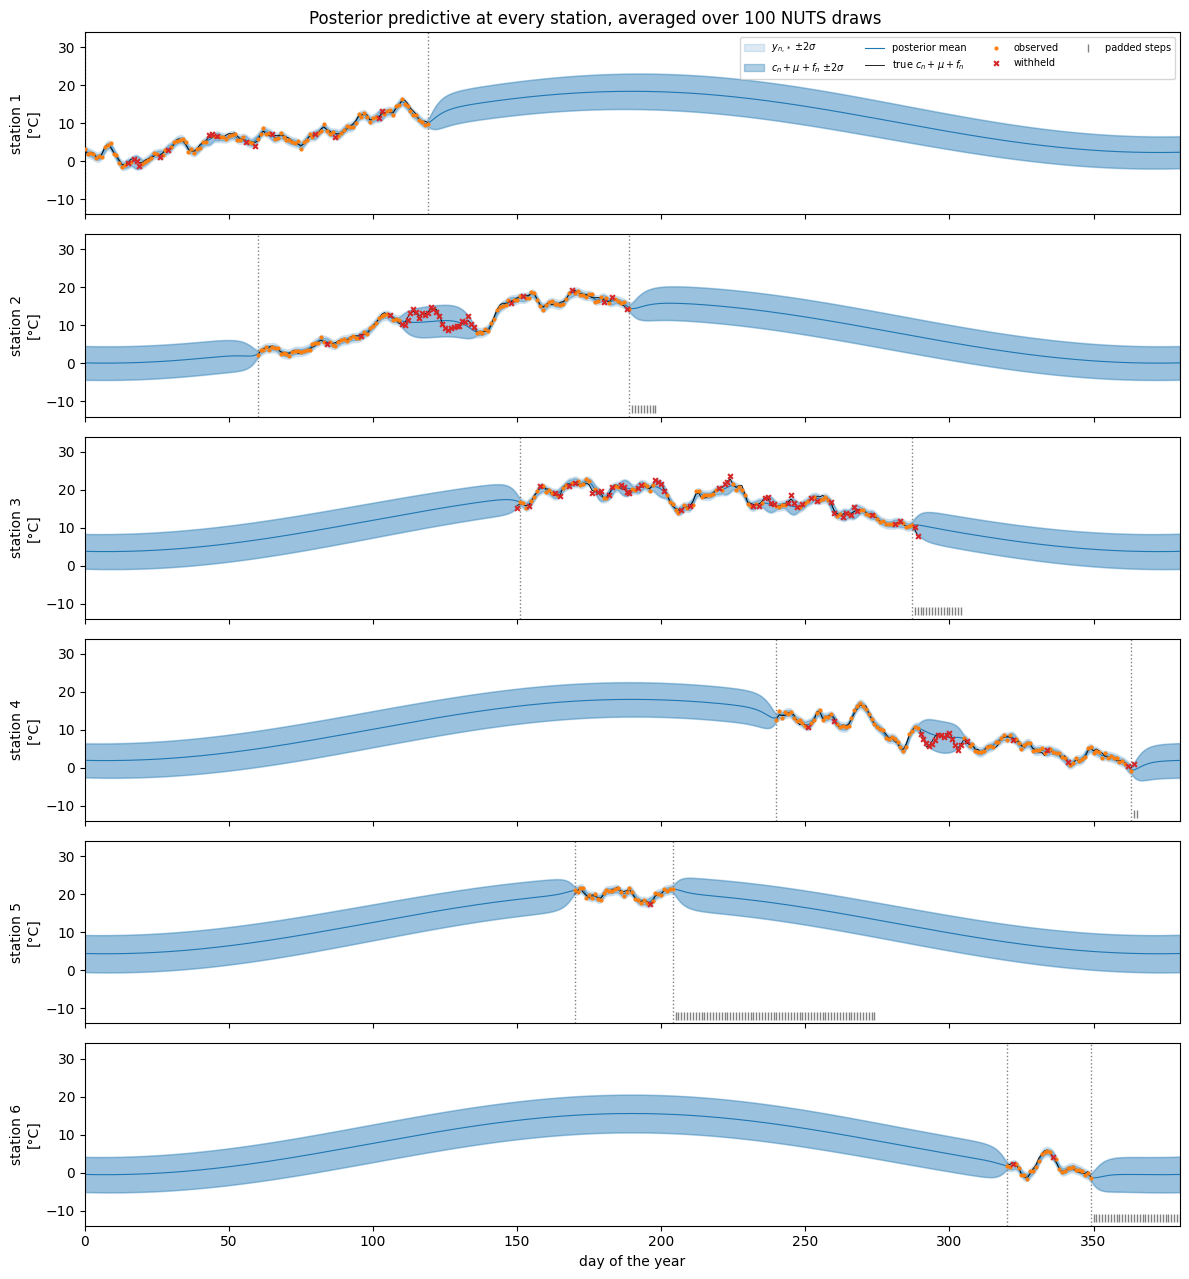

In [13]:
f_sd = np.sqrt(np.asarray(pred_f_var))  # → (N_Ω, M)
y_sd = np.sqrt(np.asarray(pred_y_var))  # → (N_Ω, M)
f_mean = np.asarray(pred_mean)  # → (N_Ω, M)
t_grid = np.asarray(t_dense)  # → (M,)

fig, axes = plt.subplots(n_stations, 1, figsize=(12, 13), sharex=True)
for n, ax in enumerate(axes):
    ax.fill_between(
        t_dense,
        f_mean[n] - 2 * y_sd[n],
        f_mean[n] + 2 * y_sd[n],
        color="C0",
        alpha=0.15,
        label=r"$y_{n,*}$ $\pm 2\sigma$",
    )
    ax.fill_between(
        t_dense,
        f_mean[n] - 2 * f_sd[n],
        f_mean[n] + 2 * f_sd[n],
        color="C0",
        alpha=0.35,
        label=r"$c_n + \mu + f_n$ $\pm 2\sigma$",
    )
    ax.plot(t_dense, f_mean[n], "C0", lw=0.8, label="posterior mean")
    days, latent = latent_per_station[n]
    ax.plot(days, latent, "k-", lw=0.6, label=r"true $c_n + \mu + f_n$")
    ax.scatter(
        times_per_station[n], y_per_station[n], c="C1", s=4, zorder=5, label="observed"
    )
    days_w, y_w, _ = withheld_per_station[n]
    ax.scatter(days_w, y_w, marker="x", c="C3", s=12, zorder=5, label="withheld")
    ax.axvline(float(times_per_station[n][0]), color="grey", ls=":", lw=1)
    ax.axvline(float(times_per_station[n][-1]), color="grey", ls=":", lw=1)
    padded_days = np.asarray(times[n])[~np.asarray(mask[n])]
    padded_days = padded_days[padded_days <= t_dense[-1]]
    ax.plot(
        padded_days,
        np.full(padded_days.shape, -12.0),
        "|",
        color="grey",
        ms=6,
        label="padded steps",
    )
    ax.set_ylim(-14, 34)
    ax.set_ylabel(f"station {n + 1}\n[°C]")
axes[0].legend(loc="upper right", fontsize=7, ncol=4)
axes[-1].set_xlabel("day of the year")
axes[-1].set_xlim(0, float(t_dense[-1]))
fig.suptitle("Posterior predictive at every station, averaged over 100 NUTS draws")
plt.tight_layout()
plt.show()

Inside each record the band is narrow and follows the observations, and it widens over the two outages (stations 2 and 4) and over the days a station missed. Before a station starts and after it stops, the posterior mean relaxes to the station's climatology $c_n + \mu(t)$, with the seasonal cycle that the network learned from all six stations. Within a few lengthscales the band widens to the stationary anomaly spread plus the uncertainty of $c_n$. Station 1, for instance, stopped on day 119, and its prediction for the rest of the year is the shared annual cycle shifted by its own offset.

Because the data are simulated, we know the values the stations would have reported on the days they missed. Below we compute, for each station, the fraction of its missed days whose value falls inside the $\pm 2\sigma$ band for $y_{n,*}$, which should be close to 95 %, and the RMSE of the posterior mean on those days.

In [14]:
# Shapes: N_w withheld days at station n; M test times on a 12-hour grid

residuals, z_scores, in_outages = [], [], []
print(
    f"{'station':<9}{'withheld':>9}{'in outage':>10}{'coverage of ±2σ':>17}{'RMSE':>9}"
)
for n in range(n_stations):
    days_w, y_w, outage_w = withheld_per_station[n]
    # day d sits at index 2d of the 12-hour grid
    grid_index = (2 * days_w).astype(int)  # → (N_w,)
    # r = y − μ̄_n,* on the withheld days
    residual = y_w - pred_mean[n, grid_index]  # → (N_w,)
    # z = r / σ_*, with σ_* the predictive standard deviation of y_n,*
    z = residual / jnp.sqrt(pred_y_var[n, grid_index])  # → (N_w,)
    residuals.append(residual)
    z_scores.append(z)
    in_outages.append(outage_w)
    # fraction of days with |z| < 2
    cover = float(jnp.mean(jnp.abs(z) < 2.0))  # → ()
    # RMSE = √(mean of r²)
    rmse = float(jnp.sqrt(jnp.mean(residual**2)))  # → ()
    print(
        f"{n + 1:<9}{days_w.shape[0]:>9}{int(outage_w.sum()):>10}"
        f"{100 * cover:>15.1f} %{rmse:>7.2f} °C"
    )
residual_all = jnp.concatenate(residuals)  # → (∑ₙ N_w,)
z_all = jnp.concatenate(z_scores)  # → (∑ₙ N_w,)
outage_all = jnp.concatenate(in_outages)  # → (∑ₙ N_w,) bool
print()
for label, sel in (
    ("outages", outage_all),
    ("random dropouts", ~outage_all),
    ("all withheld", jnp.ones_like(outage_all)),
):
    cover = float(jnp.mean(jnp.abs(z_all[sel]) < 2.0))  # → ()
    rmse = float(jnp.sqrt(jnp.mean(residual_all[sel] ** 2)))  # → ()
    print(
        f"{label:<16} n = {int(sel.sum()):>3}  "
        f"coverage of ±2σ = {100 * cover:5.1f} %  RMSE = {rmse:.2f} °C"
    )

station   withheld in outage  coverage of ±2σ     RMSE


1               16         0          100.0 %   0.71 °C


2               35        25          100.0 %   1.79 °C


3               53         0           92.5 %   1.09 °C


4               23        15           95.7 %   1.59 °C


5                1         0          100.0 %   0.57 °C


6                2         0          100.0 %   0.35 °C



outages          n =  40  coverage of ±2σ =  97.5 %  RMSE = 2.01 °C


random dropouts  n =  90  coverage of ±2σ =  95.6 %  RMSE = 0.95 °C


all withheld     n = 130  coverage of ±2σ =  96.2 %  RMSE = 1.36 °C


Over all 130 missed days, 96.2 % fall inside the $\pm 2\sigma$ band for a new observation: 97.5 % of the 40 outage days and 95.6 % of the 90 random dropouts. As in Example 1, the error is larger inside the outages (RMSE 2.01 °C) than at isolated missing days (0.95 °C). The lowest coverage is at station 3 (92.5 %), which missed 53 of its 140 days, more than any other station.

## 7. The short stations on their own

To see what pooling buys, we fit stations 5 and 6 without the network, with Example 1's model. Each station gets its own $a$, $b$, $\sigma_f^2$, $\ell$ and $\sigma_\varepsilon^2$ with Example 1's priors, and its offset is integrated out as above, so nothing is shared. The two fits then have independent posteriors. So we run them as one pair of NUTS chains on a plate of two stations (padded with `pad_sites` again), which costs one batched filter per gradient rather than two.

Note that the fit on its own has to learn the seasonal cycle and the noise from a month of data as well as the kernel. The network model gets $a$, $b$ and $\sigma_\varepsilon^2$ from all six stations, so this comparison shows everything a short record gains from the network, not only what it gains from pooling $\boldsymbol{\theta}_n$.

In [15]:
def independent_model(times, y, mask):
    # Shapes: N_Ω' = 2 stations; N' padded steps; D_θ = 5 N_Ω' = 10 sampled values

    # today (numpyro): Example 1's sample sites, once per station
    with numpyro.plate("station", times.shape[0]):
        # a_n ~ 𝒩(0, 10²)
        a = numpyro.sample("cos_amp", dist.Normal(0.0, 10.0))  # → (N_Ω',)
        # b_n ~ 𝒩(0, 10²)
        b = numpyro.sample("sin_amp", dist.Normal(0.0, 10.0))  # → (N_Ω',)
        # σ_f,n² ~ LogNormal(log 2, 1)
        variance = numpyro.sample(  # → (N_Ω',)
            "variance", dist.LogNormal(jnp.log(2.0), 1.0)
        )
        # ℓ_n ~ LogNormal(log 7, 1)
        lengthscale = numpyro.sample(  # → (N_Ω',)
            "lengthscale", dist.LogNormal(jnp.log(7.0), 1.0)
        )
        # σ_ε,n² ~ LogNormal(log 0.1, 1)
        noise_var = numpyro.sample(  # → (N_Ω',)
            "noise_var", dist.LogNormal(jnp.log(0.1), 1.0)
        )
        # today (jax)
        per_station = jax.vmap(station_log_marginal)
        # log p(y_n ∣ a_n, b_n, σ_f,n², ℓ_n, σ_ε,n²) for each station
        log_marginals = per_station(  # (N_Ω', N') → (N_Ω',)
            times, y, mask, variance, lengthscale, a, b, noise_var
        )
        # today (numpyro)
        numpyro.factor("y", log_marginals)


short = [4, 5]
# today (pyrox_ssm)
short_times, short_y, short_mask = pad_sites(  # → 3 × (N_Ω', N')
    [times_per_station[n] for n in short], [y_per_station[n] for n in short]
)
# today (numpyro)
independent_nuts = MCMC(
    NUTS(independent_model, dense_mass=True, init_strategy=init_to_median),
    num_warmup=250,
    num_samples=150,
    num_chains=2,
    chain_method="parallel",
    progress_bar=False,
)
t0 = time.perf_counter()
# today (numpyro)
independent_nuts.run(
    jr.PRNGKey(5), short_times, short_y, short_mask, extra_fields=("num_steps",)
)
jax.block_until_ready(independent_nuts.get_samples())
independent_seconds = time.perf_counter() - t0
independent_samples = independent_nuts.get_samples()  # → {name: (300, N_Ω')}
independent_extra = independent_nuts.get_extra_fields()
n_div_ind = int(independent_extra["diverging"].sum())  # → ()
n_grad_ind = int(independent_extra["num_steps"].sum())  # → ()
print(
    f"independent NUTS wall-clock: {independent_seconds:.1f} s, "
    f"{n_div_ind} divergences, {n_grad_ind / 300:.1f} leapfrog steps per draw"
)
print()
print(TABLE_HEADER)
for j, n in enumerate(short):
    for k, name in enumerate(("variance", "lengthscale")):
        truth_value = float(kernel_true[n, k])
        pooled = summarise(nuts_samples[name][:, n], truth_value)
        alone = summarise(independent_samples[name][:, j], truth_value)
        print(f"{f'{name}[{n + 1}] network':<24}{pooled}")
        print(f"{f'{name}[{n + 1}] on its own':<24}{alone}")

independent NUTS wall-clock: 20.5 s, 0 divergences, 11.6 leapfrog steps per draw

parameter                  truth          mean ± sd         90% interval
variance[5] network         2.54     3.841 ± 0.906   [  2.663,   5.108] out
variance[5] on its own      2.54     2.563 ± 1.536   [  1.030,   5.488]  in
lengthscale[5] network      3.00     4.224 ± 0.893   [  2.882,   5.745]  in
lengthscale[5] on its own    3.00     3.535 ± 2.192   [  1.372,   8.314]  in
variance[6] network         4.16     4.117 ± 1.002   [  2.854,   5.881]  in
variance[6] on its own      4.16     6.085 ± 3.639   [  2.347,  13.501]  in
lengthscale[6] network      3.62     4.253 ± 0.716   [  3.248,   5.509]  in
lengthscale[6] on its own    3.62     4.371 ± 1.268   [  2.642,   6.537]  in


The forest plot below shows every station's posterior median and 90 % interval for $\sigma_{f,n}^2$ and $\ell_n$, sorted by record length. Blue is the network model and orange, for the two short stations, the fit on their own. The black crosses are the true values, and the grey band is the posterior median and 90 % interval of the population value $\exp(\mu_{\theta,d})$.

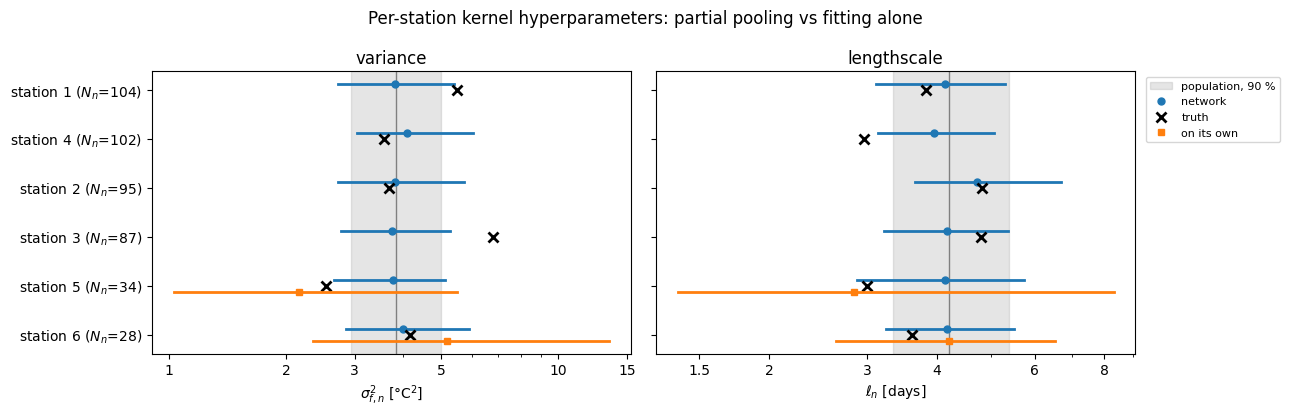

In [16]:
# Shapes: N_Ω = 6 stations; 300 draws per fit


def interval(draws):
    """Median and 90 % interval of posterior draws along the draw axis."""
    values = np.asarray(draws)
    lo, mid, hi = np.percentile(values, [5, 50, 95], axis=0)
    return lo, mid, hi


order = np.argsort(record_lengths)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, name, loc_name, k, ticks in (
    (axes[0], "variance", "variance_loc", 0, (1, 2, 3, 5, 10, 15)),
    (axes[1], "lengthscale", "lengthscale_loc", 1, (1.5, 2, 3, 4, 6, 8)),
):
    pop_lo, pop_mid, pop_hi = interval(jnp.exp(nuts_samples[loc_name]))
    ax.axvspan(pop_lo, pop_hi, color="grey", alpha=0.2, label="population, 90 %")
    ax.axvline(pop_mid, color="grey", lw=1)
    lo, mid, hi = interval(nuts_samples[name])
    for row, n in enumerate(order):
        ax.plot([lo[n], hi[n]], [row + 0.12, row + 0.12], "C0-", lw=2)
        ax.plot(mid[n], row + 0.12, "C0o", ms=5, label="network" if row == 0 else None)
        ax.plot(
            kernel_true[n, k],
            row,
            "kx",
            ms=7,
            mew=2,
            label="truth" if row == 0 else None,
        )
    ind_lo, ind_mid, ind_hi = interval(independent_samples[name])
    for j, n in enumerate(short):
        row = int(np.where(order == n)[0][0])
        ax.plot([ind_lo[j], ind_hi[j]], [row - 0.12, row - 0.12], "C1-", lw=2)
        ax.plot(
            ind_mid[j], row - 0.12, "C1s", ms=5, label="on its own" if j == 0 else None
        )
    ax.set_xscale("log")
    ax.set_xticks(ticks, [f"{tick:g}" for tick in ticks])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_title(name)
axes[0].set_yticks(
    range(n_stations),
    [f"station {n + 1} ($N_n$={record_lengths[n]})" for n in order],
)
axes[0].set_xlabel(r"$\sigma_{f,n}^2$ [°C$^2$]")
axes[1].set_xlabel(r"$\ell_n$ [days]")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8)
fig.suptitle("Per-station kernel hyperparameters: partial pooling vs fitting alone")
plt.tight_layout()
plt.show()

On their own, the short stations constrain their kernels only loosely, and we see this in the width of every orange interval. Station 6's variance has a 90 % interval of [2.35, 13.50] °C² on its own and [2.85, 5.88] °C² in the network, and station 5's lengthscale [1.37, 8.31] days on its own and [2.88, 5.75] days in the network. Over the four hyperparameters of the two short stations, the network's 90 % intervals are 1.7 to 3.7 times narrower. Station 6's estimates also move closer to the truth, as on its own a month of data puts the posterior mean of its variance at 6.09 °C² (true 4.16) and in the network at 4.12.

The price is the bias of shrinkage. Station 5 has the smallest true variance in the network (2.54 °C²). The network pulls its estimate up to 3.84, so its interval misses the truth, whereas the fit on its own has a posterior mean of 2.56 and an interval 1.8 times wider that contains it. Partial pooling trades this bias at the unusual stations for much tighter estimates at the typical ones.

The hyperparameters matter because of what they do to the predictions. Below we predict stations 5 and 6 from their fits on their own, with the same `posterior_predict`, where each draw now carries the station's own $a$, $b$ and $\sigma_\varepsilon^2$. We compare with the network's prediction over each record and the 30 days on either side. The true latent was never simulated outside a station's record, so there we draw the true climatology $c_n + \mu(t)$ as a dashed line instead.

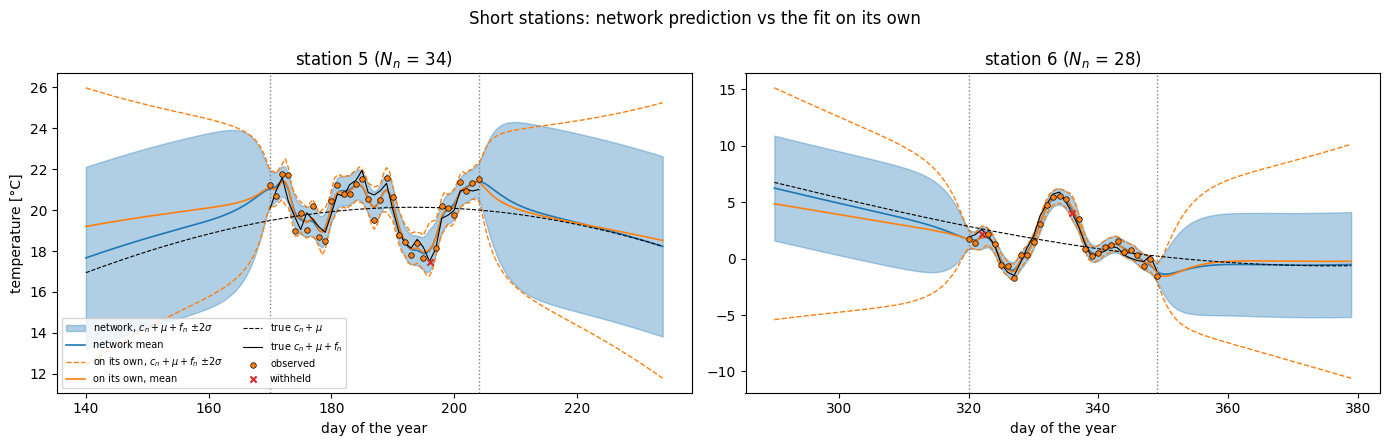

In [17]:
# Shapes: N_Ω' = 2 short stations; M test times; N_E = 100 draws

independent_draws = station_draws(independent_samples, len(short))  # → (N_Ω', N_E)
t0 = time.perf_counter()
ind_mean, ind_f_var, ind_y_var = posterior_predict(  # → 3 × (N_Ω', M)
    independent_draws, short_times, short_y, short_mask, t_dense
)
jax.block_until_ready(ind_mean)
ind_pred_seconds = time.perf_counter() - t0
ind_f_sd = np.sqrt(np.asarray(ind_f_var))  # → (N_Ω', M)
ind_y_sd = np.sqrt(np.asarray(ind_y_var))  # → (N_Ω', M)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, j, n in zip(axes, range(len(short)), short, strict=True):
    first = float(times_per_station[n][0])
    last = float(times_per_station[n][-1])
    win = (t_grid >= first - 30) & (t_grid <= last + 30)
    # c_n + μ(t), the true climatology
    true_climatology = truth_offset[n] + seasonal(  # (M,) → (M,)
        t_dense, truth_shared["cos_amp"], truth_shared["sin_amp"]
    )
    ax.fill_between(
        t_dense[win],
        (f_mean[n] - 2 * f_sd[n])[win],
        (f_mean[n] + 2 * f_sd[n])[win],
        color="C0",
        alpha=0.35,
        label=r"network, $c_n + \mu + f_n$ $\pm 2\sigma$",
    )
    ax.plot(t_dense[win], f_mean[n][win], "C0", lw=1.2, label="network mean")
    ax.plot(
        t_dense[win],
        (ind_mean[j] - 2 * ind_f_sd[j])[win],
        "C1--",
        lw=1,
        label=r"on its own, $c_n + \mu + f_n$ $\pm 2\sigma$",
    )
    ax.plot(t_dense[win], (ind_mean[j] + 2 * ind_f_sd[j])[win], "C1--", lw=1)
    ax.plot(t_dense[win], ind_mean[j][win], "C1", lw=1.2, label="on its own, mean")
    ax.plot(
        t_dense[win],
        true_climatology[win],
        color="k",
        ls="--",
        lw=0.8,
        label=r"true $c_n + \mu$",
    )
    days, latent = latent_per_station[n]
    ax.plot(days, latent, "k-", lw=0.8, label=r"true $c_n + \mu + f_n$")
    ax.scatter(
        times_per_station[n],
        y_per_station[n],
        c="C1",
        edgecolors="k",
        linewidths=0.5,
        s=16,
        zorder=5,
        label="observed",
    )
    days_w, y_w, _ = withheld_per_station[n]
    ax.scatter(days_w, y_w, marker="x", c="C3", s=20, zorder=5, label="withheld")
    ax.axvline(first, color="grey", ls=":", lw=1)
    ax.axvline(last, color="grey", ls=":", lw=1)
    ax.set_title(f"station {n + 1} ($N_n$ = {record_lengths[n]})")
    ax.set_xlabel("day of the year")
axes[0].set_ylabel("temperature [°C]")
axes[0].legend(loc="lower left", fontsize=7, ncol=2)
fig.suptitle("Short stations: network prediction vs the fit on its own")
plt.tight_layout()
plt.show()

In numbers, for the 30 days before each short record and the 30 days after it, we compare the mean half-width of the latent $\pm 2\sigma$ band and the RMSE of the posterior mean against the true climatology $c_n + \mu(t)$. Inside the record we compare the RMSE of the posterior mean against the true latent on the days the station existed.

In [18]:
# Shapes: M test times; N_Ω' = 2 short stations

print(
    f"{'station':<9}{'window':<15}{'2σ network':>12}{'2σ alone':>14}"
    f"{'RMSE network':>14}{'RMSE alone':>14}"
)
for j, n in enumerate(short):
    first = float(times_per_station[n][0])
    last = float(times_per_station[n][-1])
    # c_n + μ(t), the true climatology on the grid
    true_climatology = truth_offset[n] + seasonal(  # (M,) → (M,)
        t_dense, truth_shared["cos_amp"], truth_shared["sin_amp"]
    )
    days, latent = latent_per_station[n]
    # day d sits at index 2d of the 12-hour grid
    record_index = np.asarray(2 * days).astype(int)  # → (n_days,)
    windows = (
        ("30 d before", (t_grid >= first - 30) & (t_grid < first), true_climatology),
        ("30 d after", (t_grid > last) & (t_grid <= last + 30), true_climatology),
    )
    for label, sel, target in windows:
        # 2σ, averaged over the window
        width_net = float(jnp.mean(2 * f_sd[n][sel]))  # → ()
        width_ind = float(jnp.mean(2 * ind_f_sd[j][sel]))  # → ()
        # √(mean of (μ̄_n,* − (c_n + μ(t_*)))²)
        rmse_net = float(jnp.sqrt(jnp.mean((f_mean[n][sel] - target[sel]) ** 2)))
        rmse_ind = float(jnp.sqrt(jnp.mean((ind_mean[j][sel] - target[sel]) ** 2)))
        print(
            f"{n + 1:<9}{label:<15}{width_net:>9.2f} °C{width_ind:>11.2f} °C"
            f"{rmse_net:>11.2f} °C{rmse_ind:>11.2f} °C"
        )
    # √(mean of (μ̄_n,* − (c_n + μ + f_n))²) over the days the station existed
    rmse_net = float(jnp.sqrt(jnp.mean((f_mean[n][record_index] - latent) ** 2)))
    rmse_ind = float(jnp.sqrt(jnp.mean((ind_mean[j][record_index] - latent) ** 2)))
    # 2σ, averaged over the days the station existed
    width_net = float(jnp.mean(2 * f_sd[n][record_index]))  # → ()
    width_ind = float(jnp.mean(2 * ind_f_sd[j][record_index]))  # → ()
    print(
        f"{n + 1:<9}{'own record':<15}{width_net:>9.2f} °C{width_ind:>11.2f} °C"
        f"{rmse_net:>11.2f} °C{rmse_ind:>11.2f} °C"
    )

station  window           2σ network      2σ alone  RMSE network    RMSE alone


5        30 d before         4.09 °C       4.81 °C       0.80 °C       1.63 °C
5        30 d after          4.07 °C       4.82 °C       0.46 °C       0.35 °C


5        own record          0.75 °C       0.84 °C       0.39 °C       0.39 °C
6        30 d before         4.27 °C       7.44 °C       0.58 °C       1.37 °C
6        30 d after          4.27 °C       7.52 °C       0.56 °C       0.64 °C


6        own record          0.76 °C       0.69 °C       0.39 °C       0.39 °C


Inside the two records the predictions agree. The posterior mean is 0.39 °C RMSE from the true latent for both fits at both stations. The mean half-widths of the bands differ by about 10 % (0.75 against 0.84 °C at station 5, 0.76 against 0.69 °C at station 6), because a month of daily data pins the path down wherever there are data. The difference is away from the data. On its own, a station learns its seasonal cycle from one month, so its band keeps widening with the distance from the record. Over the 30 days on either side its mean half-width is 4.81 to 7.52 °C. The network knows the seasonal cycle from the other stations, so its band stops growing once the anomaly has forgotten the last observation, at a mean half-width of 4.07 to 4.27 °C. Its posterior mean is also closer to the true climatology in three of the four windows, for example 0.58 against 1.37 °C RMSE in the 30 days before station 6. In the fourth it is slightly further (0.46 against 0.35 °C after station 5).

## 8. Cost

Each NUTS leapfrog step costs one Kalman filter pass per station over the $N$ padded steps, plus its reverse-mode gradient. Under `jax.vmap` the stations run as one filter on a batch of $N_\Omega$ three-dimensional states, so the sequential scan over the $N$ steps is shared. Below we time one jitted log likelihood and its gradient for a single station at the padded length $N$ and for the whole network, and we list the wall-clock times of the fits and the predictions.

In [19]:
def time_grad(n_rows, repeats=20):
    # Shapes: n_rows stations (1 or N_Ω); N padded steps; 3 log parameters each
    t_rows = times[:n_rows]  # → (n_rows, N)
    y_rows = y[:n_rows]  # → (n_rows, N)
    o_rows = mask[:n_rows]  # → (n_rows, N) bool

    def neg_log_likelihood(log_params):
        params = jnp.exp(log_params)  # → (n_rows, 3)
        # today (jax)
        per_station = jax.vmap(
            station_log_marginal, in_axes=(0, 0, 0, 0, 0, None, None, 0)
        )
        # log p(y_n ∣ ·) for each row
        log_marginals = per_station(  # (n_rows, N) → (n_rows,)
            t_rows,
            y_rows,
            o_rows,
            params[:, 0],
            params[:, 1],
            truth_shared["cos_amp"],
            truth_shared["sin_amp"],
            params[:, 2],
        )
        # ℒ_NLL = −∑ₙ log p(y_n ∣ ·)
        return -einx.sum("n ->", log_marginals)

    # today (jax)
    # ℒ_NLL and its gradient, jitted once
    loss_and_grad = jax.jit(jax.value_and_grad(neg_log_likelihood))
    log_params = jnp.log(jnp.tile(jnp.array([4.0, 4.0, 0.25]), (n_rows, 1)))
    jax.block_until_ready(loss_and_grad(log_params))
    t0 = time.perf_counter()
    for _ in range(repeats):
        jax.block_until_ready(loss_and_grad(log_params))
    return (time.perf_counter() - t0) / repeats


grad_ms = {rows: 1e3 * time_grad(rows) for rows in (1, n_stations)}
for rows, ms in grad_ms.items():
    label = "one station" if rows == 1 else f"all {rows} stations"
    print(
        f"{label:<14} N = {n_padded}: {ms:6.2f} ms per log likelihood + gradient "
        f"({ms / grad_ms[1]:.1f}x one station)"
    )
print()
print(
    f"network NUTS    : {nuts_seconds:6.1f} s  "
    f"(2 chains x 400 iterations, {n_grad} leapfrog steps after warm-up)"
)
print(
    f"independent NUTS: {independent_seconds:6.1f} s  "
    f"(2 short stations, 2 chains x 400 iterations, {n_grad_ind} leapfrog steps)"
)
print(
    f"network prediction    : {pred_seconds:5.1f} s  "
    f"({n_stations} stations x {N_DRAWS} draws x {t_dense.shape[0]} times, with JIT)"
)
print(
    f"independent prediction: {ind_pred_seconds:5.1f} s  "
    f"(2 stations x {N_DRAWS} draws x {t_dense.shape[0]} times, with JIT)"
)

one station    N = 104:   2.87 ms per log likelihood + gradient (1.0x one station)
all 6 stations N = 104:   4.29 ms per log likelihood + gradient (1.5x one station)

network NUTS    :   97.5 s  (2 chains x 400 iterations, 6660 leapfrog steps after warm-up)
independent NUTS:   20.5 s  (2 short stations, 2 chains x 400 iterations, 3492 leapfrog steps)
network prediction    :   7.0 s  (6 stations x 100 draws x 761 times, with JIT)
independent prediction:   4.0 s  (2 stations x 100 draws x 761 times, with JIT)


One log likelihood and its gradient cost 2.87 ms for one station and 4.29 ms for all six, so six times the records cost 1.5 times as much. This is because the vmapped filters share the sequential scan over the $N$ padded steps. Most of the cost of the network fit is in the number of gradients that NUTS needs for the hierarchical posterior (22.2 leapfrog steps per draw after warm-up), not in the extra stations. The network fit took 97.5 s with the two chains on two cores, and the two short stations on their own took 20.5 s. The predictions are cheap next to the fits: 7.0 s for 100 draws at all six stations on the 761-point grid, and 4.0 s for the two short stations on their own, both including JIT compilation.

## Summary

- Ragged station records go into one model through `pad_sites`, which pads every record after its last day and returns the mask. The masked padding changes no station's log marginal, so the gaps stay in the days and the padding stays out of the likelihood.
- A hierarchical Markov-GP model is a plain NumPyro function: global sample sites, a `numpyro.plate` over stations, a non-centred draw of each station's kernel hyperparameters around the population, and `MarkovGPPrior.log_marginal(..., mask=...)` vmapped over the stations into one factor site.
- The latent paths and the station offsets stay integrated out, so NUTS runs on $7 + 2 N_\Omega$ values for any record length. The network fit took 97.5 s of NUTS on CPU, and one gradient over six stations costs 1.5 times one station.
- The two short stations borrow strength from the network: the 90 % intervals of their kernel hyperparameters are 1.7 to 3.7 times narrower than when each is fitted on its own. With six stations the population spread is poorly known (posterior mean 0.16 against a true 0.3), so the model also pulls unusual stations towards the population, and four of the twelve per-station intervals miss the truth on that side.
- `MarkovGPPrior.condition(..., mask=...).predict(...)`, vmapped over posterior draws and stations, predicts every station through its gaps and beyond its record, and 96.2 % of the 130 withheld days fall inside the $\pm 2\sigma$ band for a new observation. Away from their records, the short stations' bands in the network have a mean half-width of 4.07 to 4.27 °C against 4.81 to 7.52 °C on their own, because the seasonal cycle comes from the whole network.

The next example keeps the stations but adds a regional anomaly that all of them share, on top of each station's own anomaly. For the single-station model and its predictions see [Example 1](ssm_one_site.ipynb).